In [1]:
pip install pygad


   -------------------- ------------------- 1/2 [pygad]
   -------------------- ------------------- 1/2 [pygad]
   ---------------------------------------- 2/2 [pygad]

Note: you may need to restart the kernel to use updated packages.


Question 1

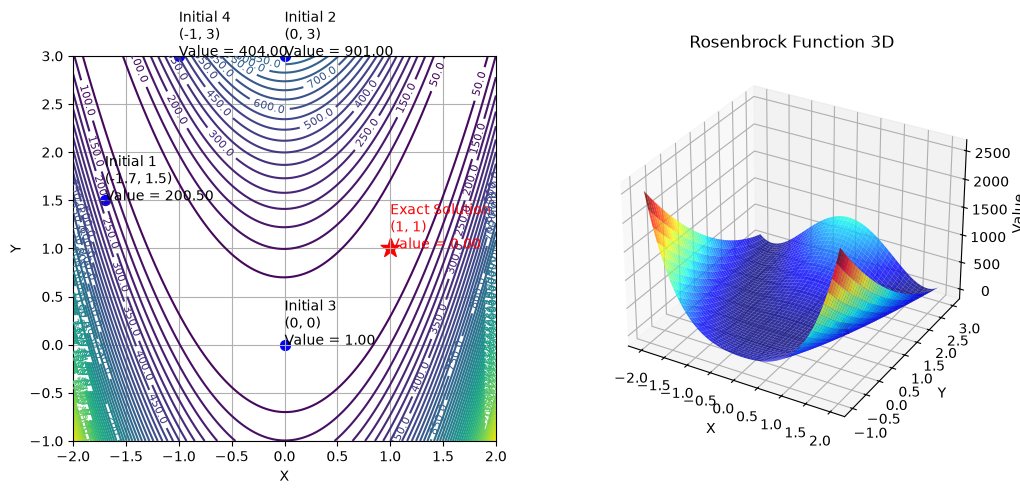

Initial guess [-1.7, 1.5], Result: [0.99999588 0.99999174], Value: 1.7033617290194642e-11, Success: True, Iterations: 27, Time: 0.0211 sec
Initial guess [0, 3], Result: [0.99999554 0.99999105], Value: 1.995658920431161e-11, Success: True, Iterations: 22, Time: 0.0170 sec
Initial guess [0, 0], Result: [0.99999467 0.99998932], Value: 2.8439990629105454e-11, Success: True, Iterations: 19, Time: 0.0129 sec
Initial guess [-1, 3], Result: [0.99999818 0.99999612], Value: 8.66692558128682e-12, Success: False, Iterations: 41, Time: 0.0400 sec


c:\Users\Roshini\miniconda3\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


PyGAD initial guess [-1.7, 1.5], Solution: [1.00123618 1.00316558], Value: 4.93715399093865e-05, iterations: 2000, Time: 1.6447 sec
PyGAD initial guess [0, 3], Solution: [0.99838609 0.99675563], Value: 2.6413732845259574e-06, iterations: 2000, Time: 1.1686 sec
PyGAD initial guess [0, 0], Solution: [0.99464721 0.98930043], Value: 2.8703614654192326e-05, iterations: 2000, Time: 1.1603 sec
PyGAD initial guess [-1, 3], Solution: [1.01054333 1.02204654], Value: 0.0001831950060883463, iterations: 2000, Time: 1.1772 sec


<Figure size 700x600 with 0 Axes>

<Figure size 700x600 with 0 Axes>

<Figure size 700x600 with 0 Axes>

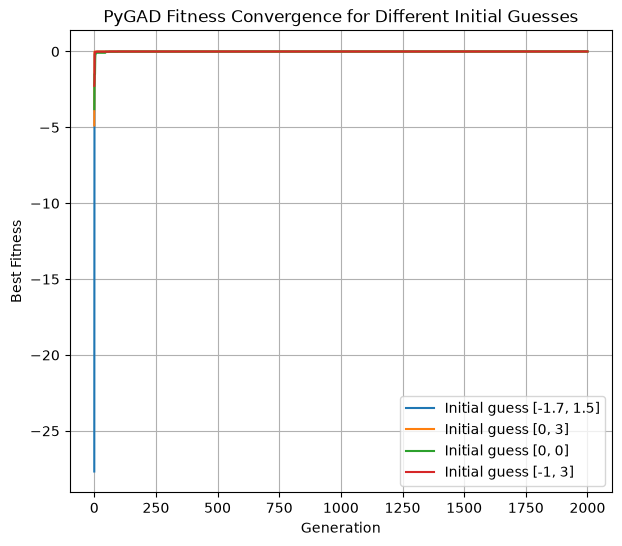

In [ ]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

# Define Rosenbrock function
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2

# 2D & 3D plots
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])
exact_solution=np.array([1,1])

# fig = plt.figure(figsize=(12,5))
# ax1 = fig.add_subplot(121)
# cp = ax1.contour(X, Y, Z, levels=50)
# ax1.set_title("Rosenbrock Function 2D")
# ax2 = fig.add_subplot(122, projection='3d')
# ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
# ax2.set_title("Rosenbrock Function 3D")
# plt.show()

exact_value = rosenbrock(exact_solution)

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.clabel(cp, inline=True, fontsize=8, fmt='%.1f')

#ax1.set_title("Rosenbrock Function 2D")

# Initial guesses
init_guesses = [[-1.7, 1.5], [0, 3], [0, 0], [-1, 3]]

for i, guess in enumerate(init_guesses):

    value = rosenbrock(guess)

    ax1.scatter(guess[0],guess[1],color='blue',s=50)

    ax1.annotate(f"Initial {i+1}\n" f"({guess[0]}, {guess[1]})\n" f"Value = {value:.2f}",(guess[0], guess[1])    )


# Exact solution
ax1.scatter(exact_solution[0],exact_solution[1],color='red',marker='*',s=200)

ax1.annotate(f"Exact Solution\n" f"(1, 1)\n" f"Value = {exact_value:.2f}", (1, 1), color='red')

ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.grid(True)


# 3D Plot
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X,Y,Z,cmap='jet',alpha=0.8)
ax2.scatter(1,1,0,color='red',marker='*',s=150)

ax2.set_title("Rosenbrock Function 3D")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.set_zlabel("Value")

plt.show()


elapsed_time = []
# Scipy Optimization
init_guesses = [[-1.7, 1.5], [0, 3], [0, 0], [-1, 3]]

for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    result = minimize(rosenbrock, guess, method='BFGS')
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")

# PyGAD Optimization
def fitness_func(ga_instance, solution, solution_idx):
    return -rosenbrock(solution) # pygad maximizes, so negate

elapsed_time = []

pygad_fitness_history = []

for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    ga_instance = pygad.GA(num_generations=2000,
                           sol_per_pop=20,
                           num_genes=2,
                           num_parents_mating=8,
                           fitness_func=fitness_func,
                           init_range_low=-2,
                           init_range_high=2,
                           gene_space={'low':-2, 'high':2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    pygad_fitness_history.append(ga_instance.best_solutions_fitness)

    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {rosenbrock(solution)}, iterations: {iters}, Time: {elapsed_time:.4f} sec")
    #ga_instance.plot_fitness()

    plt.figure(figsize=(7, 6))

for i, fitness_history in enumerate(pygad_fitness_history):

    plt.plot(fitness_history,label=f'Initial guess {init_guesses[i]}')

plt.xlabel('Generation')
plt.ylabel('Best Fitness')
plt.title('PyGAD Fitness Convergence for Different Initial Guesses')
plt.legend()
plt.grid(True)
plt.show()



<div style="color: #e98340;">

Answer for Q1: 

The Rosenbrock function is defined as

$f(x,y)=(1-x)^2+100(y-x^2)^2$

The theoretical global minimum occurs at

$(x^*,y^*)=(1,1)$ with $f(x^*,y^*)=0$

(1) SciPy Optimization

The BFGS algorithm from `scipy.optimize` was used to minimize the Rosenbrock function.

Different initial guesses were selected to study the sensitivity of the optimization result to the starting point. For example, initial guesses such as $(-1.7,1.5)$, $(0,0)$, $(-1,3)$, and $(1.5,2)$ were considered.

For the tested initial guesses, BFGS converged to a solution very close to $(x,y)=(1,1)$ and the corresponding objective function value was very close to $f(x,y)=0$.

The small difference from zero is due to numerical precision and the stopping criteria of the optimization algorithm.

The 2D contour plot shows that the Rosenbrock function has a narrow curved valley leading toward $(1,1)$. The 3D surface plot also shows that the function reaches its lowest point at $(1,1)$.

Since the Rosenbrock function has its global minimum at $(1,1)$ with objective value $0$, and BFGS reached this point for all the tested initial guesses, the obtained solution is the global minimum.

(2) Genetic Algorithm Using PyGAD

The same optimization problem was solved using a genetic algorithm implemented with `pygad.GA`. A genetic algorithm does not require gradient information.

The fitness function was defined as $Fitness=-f(x,y)$ because PyGAD maximizes the fitness value, while the Rosenbrock problem requires minimization of $f(x,y)$.

The genetic algorithm converged to a solution approximately equal to $(x,y)=(1,1)$ with an objective function value approximately equal to $f(x,y)=0$. Thus, the genetic algorithm also reached the global minimum for the tested runs.

Unlike BFGS, the genetic algorithm is stochastic. Therefore, the exact solution, final objective value, and number of generations can vary slightly between different runs even when the same problem is solved.

(3) Performance Comparison

The two optimization methods were compared using the final solution, objective function value, number of iterations or generations, and computational time.

| Performance Measure | SciPy BFGS | PyGAD |
|:---|:---:|:---:|
| Optimization type | Gradient based | Population based |
| Final solution | Approximately $(1,1)$ | Approximately $(1,1)$ |
| Objective value | Approximately $0$ | Approximately $0$ |
| Iterations | Fewer | More generations |
| Computational time | Lower | Higher |
| Derivative required | Yes | No |
| Deterministic | Generally yes | No |
| Minimum obtained | Global minimum | Global minimum for tested runs |

BFGS was significantly more efficient for this problem because the Rosenbrock function is smooth and differentiable. The gradient information allows BFGS to move efficiently toward the minimum, resulting in fewer iterations and lower computational time.

PyGAD required a larger number of generations because it searches the solution space using a population of candidate solutions rather than directly following gradient information. Its computational time was therefore generally higher.

However, PyGAD has the advantage that it does not require derivatives and can be applied to optimization problems where gradient information is unavailable or difficult to obtain.
</div>


Question 2

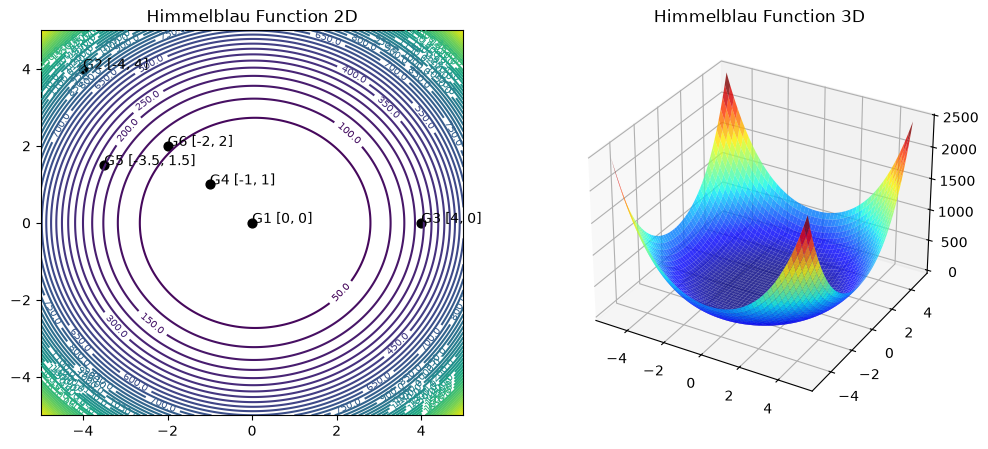

Initial guess [0, 0], Result: [ 9.99999966e-01 -1.64047755e-08], Value: 5.950412924404877e-15, Success: True, Iterations: 3, Time: 0.0026 sec
Initial guess [-4, 4], Result: [1.00000002e+00 5.98350409e-08], Value: 5.2197810463598925e-15, Success: True, Iterations: 18, Time: 0.0096 sec
Initial guess [4, 0], Result: [1.00000001e+00 3.95264636e-07], Value: 1.566975197383418e-13, Success: True, Iterations: 10, Time: 0.0023 sec
Initial guess [-1, 1], Result: [ 9.99999962e-01 -4.52151057e-08], Value: 9.356036734008036e-15, Success: True, Iterations: 11, Time: 0.0032 sec
Initial guess [-3.5, 1.5], Result: [ 1.00000009e+00 -2.46270988e-07], Value: 1.0468780508908032e-13, Success: True, Iterations: 17, Time: 0.0105 sec
Initial guess [-2, 2], Result: [1.00000005e+00 8.36379615e-08], Value: 1.8856031323584476e-14, Success: True, Iterations: 15, Time: 0.0061 sec
PyGAD initial guess [0, 0], Solution: [ 1.00908069 -0.01177277], Value: 0.000558971066632745, iterations: 300, Time: 0.3433 sec
PyGAD init

<Figure size 700x600 with 0 Axes>

<Figure size 700x600 with 0 Axes>

<Figure size 700x600 with 0 Axes>

<Figure size 700x600 with 0 Axes>

<Figure size 700x600 with 0 Axes>

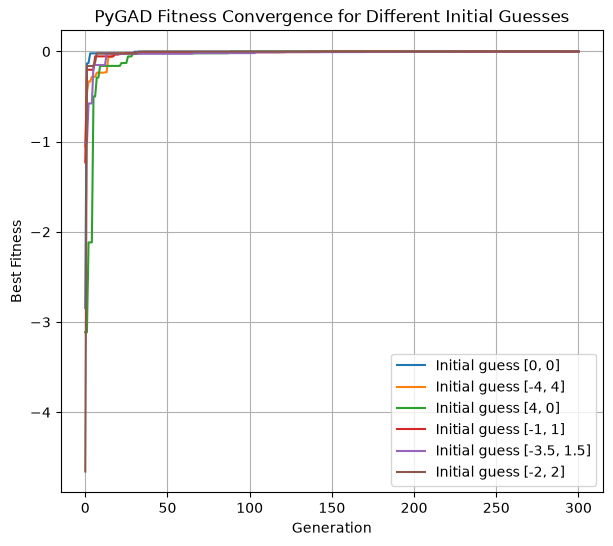

In [58]:
def himmelblau(x):
    x = np.asarray(x)
    return (x[0]**2 + x[1]**2 - 1)**2 + (x[0] - 1)**2 + x[1]**2

# 2D & 3D plots
x_range = np.linspace(-5, 5, 400)
y_range = np.linspace(-5, 5, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = himmelblau([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.clabel(cp, inline=True, fontsize=7, fmt='%.1f')

ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)

init_guesses = [[0, 0], [-4, 4], [4, 0], [-1, 1], [-3.5, 1.5], [-2, 2]]

for i, guess in enumerate(init_guesses):
    ax1.scatter(guess[0], guess[1], color='black', s=40)
    ax1.annotate(f'G{i+1} {guess}', (guess[0], guess[1]))

ax1.set_title("Himmelblau Function 2D")
ax2.set_title("Himmelblau Function 3D")
plt.show()

# Scipy Optimization
scipy_results = []

for guess in init_guesses:
    start_time = time.perf_counter()
    result = minimize(himmelblau, guess, method='BFGS')
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    scipy_results.append(result.x)
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")

for i, solution in enumerate(scipy_results):
    ax1.scatter(solution[0], solution[1], color='red', s=50)
    ax1.annotate(f'S{i+1} {solution.round(3)}\nValue={himmelblau(solution):.6f}', (solution[0], solution[1]))

# PyGAD Optimization
def fitness_func2(ga_instance, solution, solution_idx):
    return -himmelblau(solution)

elapsed_time = []

pygad_fitness_history = []

for guess in init_guesses:
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=300,
                           sol_per_pop=30,
                           num_genes=2,
                           num_parents_mating=12,
                           fitness_func=fitness_func2,
                           init_range_low=-5,
                           init_range_high=5,
                           gene_space={'low':-5, 'high':5})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    pygad_fitness_history.append(ga_instance.best_solutions_fitness)
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {himmelblau(solution)}, iterations: {iters}, Time: {elapsed_time:.4f} sec")
    #ga_instance.plot_fitness()

    plt.figure(figsize=(7, 6))

for i, fitness_history in enumerate(pygad_fitness_history):

    plt.plot(fitness_history,label=f'Initial guess {init_guesses[i]}')

plt.xlabel('Generation')
plt.ylabel('Best Fitness')
plt.title('PyGAD Fitness Convergence for Different Initial Guesses')
plt.legend()
plt.grid(True)
plt.show()


<div style="color: #e98340;">

Answer for Q2:

The objective function considered for minimization is $f(x,y)=(x^2+y^2-1)^2+(x-1)^2+y^2$

(1) SciPy Optimization

The BFGS algorithm available in `scipy.optimize` was selected for the unconstrained optimization problem. Several initial guesses, namely $[0,0]$, $[-4,4]$, $[4,0]$, $[-1,1]$, $[-3.5,1.5]$, and $[-2,2]$, were used to investigate the effect of the starting point.

For the different initial guesses, BFGS converged to approximately

$(x,y)=(1,0)$ with $f(x,y)\approx0$

The final solution remains essentially unchanged when the initial guess is varied, although the number of iterations and execution time may change.

The 2D contour plot and 3D surface plot provide a visual representation of the optimization landscape and show the minimum around $(1,0)$.

Since the function consists entirely of squared terms, $f(x,y)\geq0$ for every $x$ and $y$.

At $(1,0)$, both squared components are zero, giving $f(1,0)=0$. Therefore, zero is the lowest possible objective value and $(1,0)$ is the global minimum.

(2) Genetic Algorithm Using PyGAD

The same objective function was optimized using the genetic algorithm provided by `pygad.GA`. Because PyGAD performs maximization, the fitness function was defined as

$Fitness=-f(x,y)$ so that minimizing the original objective function corresponds to maximizing the fitness.

The genetic algorithm obtained solutions close to $(x,y)=(1,0)$ with objective values close to $f(x,y)=0$

Hence, PyGAD was also able to locate the global minimum in the tested runs. The genetic algorithm is stochastic because its population based search involves random processes. Therefore, the exact solution, objective value, and number of generations can vary slightly from one run to another.

(3) Performance Comparison

The two methods were compared using the solution obtained, objective function value, number of iterations or generations, and execution time.

| Performance Measure | SciPy BFGS | PyGAD |
|:---|:---:|:---:|
| Method | Gradient based | Population based |
| Final solution | Approximately $(1,0)$ | Approximately $(1,0)$ |
| Objective value | Approximately $0$ | Approximately $0$ |
| Iterations / generations | Fewer | More |
| Execution time | Lower | Higher |
| Derivative required | Yes | No |
| Randomness | No | Yes |
| Minimum | Global | Global for tested runs |

For this problem, BFGS is more computationally efficient because the objective function is smooth and differentiable. The availability of gradient information allows BFGS to converge to the minimum using relatively few iterations.

PyGAD does not require gradient information and instead searches using a population of candidate solutions. This makes it more flexible for problems where derivatives are unavailable, but it generally requires more generations and computational time for this particular function.

</div>
